# Explainable AI: Understanding Machine Learning and Deep Learning Predictions

**A hands-on Jupyter notebook for graduate ML / AI classes**  
**Estimated teaching time:** 2.5–3 hours, including exercises  
**Prerequisites:** Python, train/test split, classifiers, basic neural networks

> **Big question:** A model can predict accurately. But **why** did it make this particular prediction, and **should we trust that explanation**?

### Learning outcomes
By the end, you should be able to:
1. Distinguish **global vs. local** and **intrinsic vs. post-hoc** explanations.
2. Explain and implement **linear coefficients, permutation importance, PDP/ICE, and SHAP** for tabular ML.
3. Implement **gradient saliency, Integrated Gradients, and occlusion** for image DL.
4. Challenge an explanation's **faithfulness, stability, plausibility, and actionability**.
5. Make a defensible choice of explanation method for a real stakeholder.

**Datasets:** scikit-learn breast-cancer features (tabular) and handwritten digits (8×8 images). They are bundled with scikit-learn, so no dataset download is required. The first dataset is **for teaching only—not a clinical tool or medical recommendation**.

**Run:** Kernel → Restart & Run All. The neural network runs on CPU; SHAP is optional.

## 0 · Environment and reproducibility

Core packages: `numpy`, `pandas`, `matplotlib`, `scikit-learn`, `torch`. Optional: `shap`.

If missing, run in a separate notebook cell:

```python
%pip install numpy pandas matplotlib scikit-learn torch shap
```

The optional SHAP section skips gracefully when SHAP is unavailable. The core lesson needs no web connection once packages are installed.

In [1]:
import copy
import random
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from sklearn.datasets import load_breast_cancer, load_digits
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, roc_auc_score, confusion_matrix
from sklearn.inspection import permutation_importance, PartialDependenceDisplay

import torch
from torch import nn
from torch.utils.data import TensorDataset, DataLoader

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
# Limits oversubscription on CPU-only classroom laptops.
torch.set_num_threads(min(2, torch.get_num_threads()))

plt.rcParams.update({"figure.figsize": (8, 4.5), "axes.grid": True, "grid.alpha": 0.18})
print(f"NumPy {np.__version__} | scikit-learn loaded | PyTorch {torch.__version__}")
print("Device: CPU (GPU not needed)")

NumPy 2.3.5 | scikit-learn loaded | PyTorch 2.10.0+cpu
Device: CPU (GPU not needed)


## 1 · The explanation landscape

A useful starting point is **two independent axes**:

| | Global: behavior over many observations | Local: one prediction |
|---|---|---|
| **Intrinsically interpretable** | Coefficients in a small linear model, decision rules | Per-feature terms in a linear prediction |
| **Post-hoc** | Permutation importance; partial dependence (PDP) | SHAP; saliency; Integrated Gradients; occlusion |

**Intrinsic ≠ automatically trustworthy.** A simple interpretable model can still learn shortcuts, be miscalibrated, or exploit leakage.

**What an explanation can mean:**
- **Association:** what features are predictive together with other features?
- **Model reliance:** which information does the *fitted model* use?
- **Attribution:** how does this input affect the *model's score*, relative to a reference?
- **Intervention / causality:** what *would truly happen* if the world changed? **This is not established by normal feature attributions.**

### Think before coding
**Question:** If a model attends to a tumor-size feature, does that prove reducing the feature would change a real patient's outcome?  
**Answer:** No. An explanation of a predictive model is not a causal estimate or treatment recommendation.

## 2 · Tabular machine learning: one dataset, two models

We train a standardized **logistic regression** (easier to inspect) and a **random forest** (more flexible, less directly interpretable). We use a stratified held-out test set and never train on that test set.

**Target:** scikit-learn labels `0 = malignant`, `1 = benign`. This label direction matters for interpreting coefficient signs.

In [2]:
raw = load_breast_cancer(as_frame=True)
X = raw.data.copy()
y = raw.target.copy()
feature_names = X.columns.tolist()

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=SEED
)

logistic = Pipeline([
    ("scale", StandardScaler()),
    ("classifier", LogisticRegression(max_iter=3000, random_state=SEED)),
])
forest = RandomForestClassifier(
    n_estimators=150, min_samples_leaf=2, random_state=SEED, n_jobs=2
)
logistic.fit(X_train, y_train)
forest.fit(X_train, y_train)

results = []
for name, estimator in [("Logistic regression", logistic), ("Random forest", forest)]:
    y_pred = estimator.predict(X_test)
    positive_prob = estimator.predict_proba(X_test)[:, 1]
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "ROC-AUC": roc_auc_score(y_test, positive_prob),
    })
display(pd.DataFrame(results).round(3))
print(f"Train: {len(X_train)} rows | Test: {len(X_test)} rows | Features: {X.shape[1]}")
print("Class 0 = malignant; class 1 = benign")

,Model,Accuracy,ROC-AUC
0,Logistic regression,0.986,0.998
1,Random forest,0.958,0.994


Train: 426 rows | Test: 143 rows | Features: 30
Class 0 = malignant; class 1 = benign


### 2.1 Intrinsic explanation: logistic coefficients

For standardized input features, logistic regression produces the **log-odds** of the positive class:

\[
\log\frac{P(y=1\mid x)}{1-P(y=1\mid x)} = b + \sum_j w_j z_j
\]

where \(z_j\) is the standardized feature. A positive \(w_j\) increases the **model's log-odds of benign** when other standardized features are held fixed. Negative means the opposite.

**Caveats:** coefficients depend on feature scaling, correlations, and regularization. Their magnitude is **not causal importance**, and a coefficient is not the average change in probability.

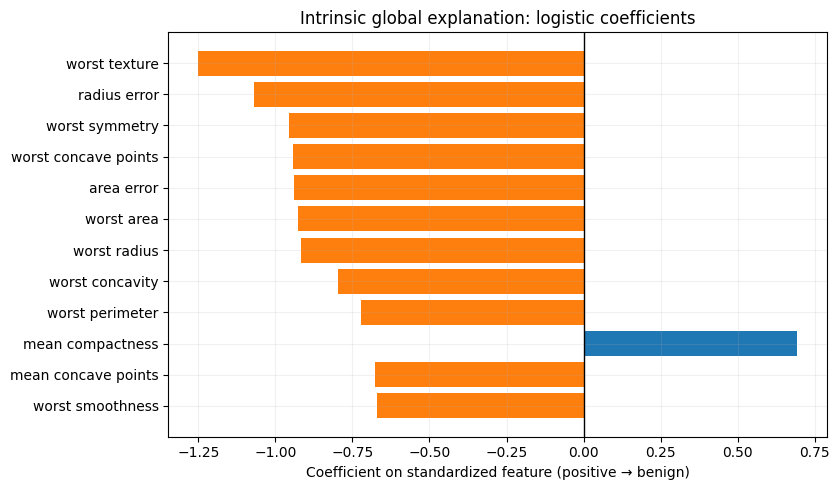

In [3]:
coef = pd.Series(logistic.named_steps["classifier"].coef_.ravel(), index=feature_names)
strongest = coef.abs().nlargest(12).sort_values().index
fig, ax = plt.subplots(figsize=(8.5, 5))
colors = np.where(coef.loc[strongest] > 0, "tab:blue", "tab:orange")
ax.barh(strongest, coef.loc[strongest], color=colors)
ax.axvline(0, color="black", lw=1)
ax.set_xlabel("Coefficient on standardized feature (positive → benign)")
ax.set_title("Intrinsic global explanation: logistic coefficients")
plt.tight_layout()
plt.show()

### 2.2 A *local* additive explanation for logistic regression

A global coefficient is the same for everyone, but each person's **contribution** is \(w_j z_j\). Add these contributions and the intercept to recover the *exact model logit* for one observation. This is an exact algebraic decomposition, not a medical explanation.

Actual class: 1 | Model predicted class: 1
Intercept: +0.281 | Sum of contributions: +3.161
Reconstructed log-odds: +3.442 | Direct model log-odds: +3.442


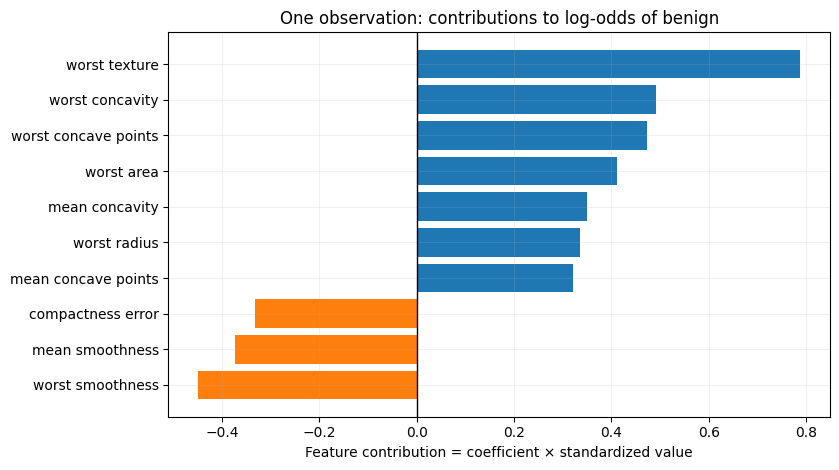

In [4]:
example_i = 0
x_one = X_test.iloc[[example_i]]
z_one = logistic.named_steps["scale"].transform(x_one)[0]
w = logistic.named_steps["classifier"].coef_[0]
b = float(logistic.named_steps["classifier"].intercept_[0])
contributions = pd.Series(w * z_one, index=feature_names)
logit_from_parts = b + contributions.sum()
logit_from_model = float(logistic.decision_function(x_one)[0])

assert np.isclose(logit_from_parts, logit_from_model)
print(f"Actual class: {int(y_test.iloc[example_i])} | Model predicted class: {int(logistic.predict(x_one)[0])}")
print(f"Intercept: {b:+.3f} | Sum of contributions: {contributions.sum():+.3f}")
print(f"Reconstructed log-odds: {logit_from_parts:+.3f} | Direct model log-odds: {logit_from_model:+.3f}")

local_top = contributions.loc[contributions.abs().nlargest(10).index].sort_values()
fig, ax = plt.subplots(figsize=(8.5, 4.8))
ax.barh(local_top.index, local_top.values,
        color=np.where(local_top.values > 0, "tab:blue", "tab:orange"))
ax.axvline(0, color="black", lw=1)
ax.set_title("One observation: contributions to log-odds of benign")
ax.set_xlabel("Feature contribution = coefficient × standardized value")
plt.tight_layout()
plt.show()

### 2.3 Post-hoc *global* explanation: permutation importance

**Experiment:** take a held-out column, shuffle it, and evaluate how much the fitted model's score worsens. Repeat the shuffle to estimate variability.

\[
\text{Importance}_j \approx \text{Score}(X_{test}) -
\text{Score}(X_{test}\text{ with column }j\text{ shuffled})
\]

**What it answers:** Which variables does *this fitted model* rely on for *this test distribution and metric*?

**What it does not answer:** Which variables are causal, independently meaningful, or safe to change. Correlated features can compensate for each other; shuffled rows can be unrealistic.

,feature,mean_AUC_drop,std
22,worst perimeter,0.0042,0.0017
27,worst concave points,0.0029,0.0013
23,worst area,0.0024,0.0007
7,mean concave points,0.0011,0.0005
21,worst texture,0.0008,0.0007
6,mean concavity,0.0006,0.0004
26,worst concavity,0.0004,0.0005
24,worst smoothness,0.0002,0.0003
1,mean texture,0.0001,0.0006
29,worst fractal dimension,0.0000,0.0000


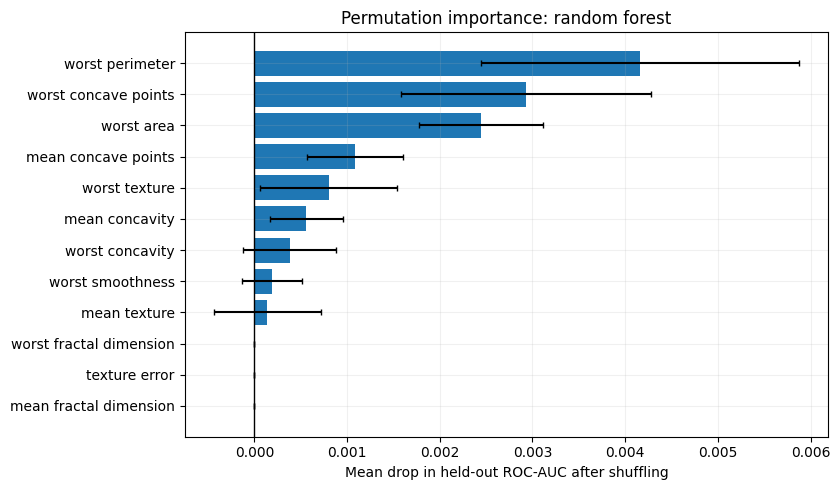

In [5]:
perm = permutation_importance(
    forest, X_test, y_test, scoring="roc_auc",
    n_repeats=6, random_state=SEED, n_jobs=2,
)
perm_df = pd.DataFrame({
    "feature": feature_names,
    "mean_AUC_drop": perm.importances_mean,
    "std": perm.importances_std,
}).sort_values("mean_AUC_drop", ascending=False)

display(perm_df.head(10).round(4))
plot_df = perm_df.head(12).iloc[::-1]
fig, ax = plt.subplots(figsize=(8.5, 5))
ax.barh(plot_df["feature"], plot_df["mean_AUC_drop"],
        xerr=plot_df["std"], capsize=2, color="tab:blue")
ax.axvline(0, color="black", lw=1)
ax.set_xlabel("Mean drop in held-out ROC-AUC after shuffling")
ax.set_title("Permutation importance: random forest")
plt.tight_layout()
plt.show()

### 2.4 Post-hoc *global* explanations: PDP and ICE

A **partial dependence plot (PDP)** varies one feature across a grid and *averages* the model's predicted response across observations. **Individual conditional expectation (ICE)** plots show each observation's response separately.

**Look for:** Does the average curve hide very different individual behaviors? Note that we are changing feature values mathematically, not performing real-world interventions.

In scikit-learn's binary classification display, the plotted response generally represents the model's positive-class score/probability depending on estimator and settings; here we use `response_method="predict_proba"` to request **P(benign)** explicitly.

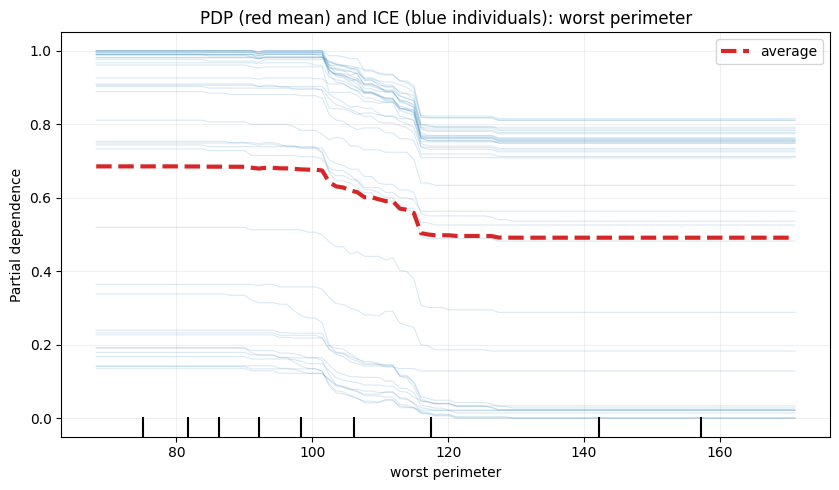

In [6]:
feature_to_vary = perm_df.iloc[0]["feature"]
fig, ax = plt.subplots(figsize=(8.5, 5))
PartialDependenceDisplay.from_estimator(
    forest, X_test,
    features=[feature_to_vary],
    kind="both", subsample=40, random_state=SEED,
    response_method="predict_proba", ax=ax,
    line_kw={"color": "tab:red", "linewidth": 3},
    ice_lines_kw={"color": "tab:blue", "alpha": 0.16, "linewidth": 0.8},
)
ax.set_title(f"PDP (red mean) and ICE (blue individuals): {feature_to_vary}")
ax.set_ylabel("Model prediction: P(benign)")
plt.tight_layout()
plt.show()

### 2.5 Local SHAP explanation (optional)

SHAP attributes a model output to features **relative to a background/reference distribution**. Roughly:

\[
 f(x) = E_{background}[f(X)] + \sum_j \phi_j
\]

The decomposition depends on the explainer, output scale, and reference distribution. For this example, we explain the logistic model's **raw log-odds**, not probability. This is *not* equivalent to identifying causal features.

This cell uses the transformed (standardized) data and a small training-data background for speed. It skips when `shap` is not installed.

/opt/pyvenv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


SHAP output: logistic raw log-odds; expected value + SHAP sum ≈ model logit.
SHAP reconstruction: 3.4417
Model logit:          3.4417


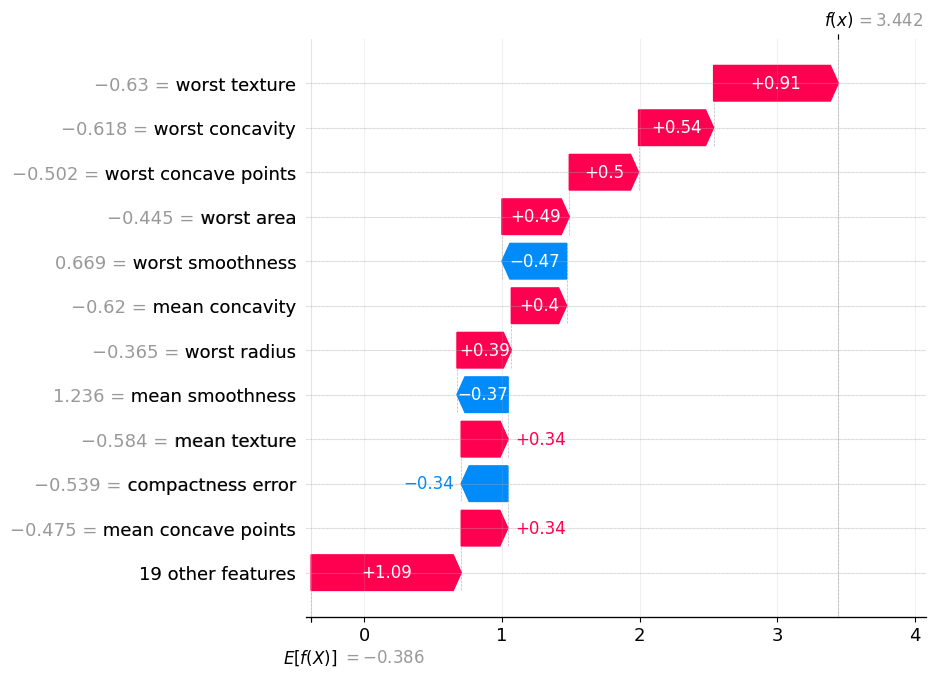

In [7]:
try:
    import shap
except ImportError:
    print("SHAP not installed. Optional: %pip install shap")
else:
    scaler = logistic.named_steps["scale"]
    bg = pd.DataFrame(scaler.transform(X_train), columns=feature_names, index=X_train.index)
    point = pd.DataFrame(scaler.transform(x_one), columns=feature_names, index=x_one.index)
    explainer = shap.Explainer(logistic.named_steps["classifier"], bg.sample(100, random_state=SEED))
    sv = explainer(point)
    print("SHAP output: logistic raw log-odds; expected value + SHAP sum ≈ model logit.")
    print(f"SHAP reconstruction: {float(np.asarray(sv.base_values).ravel()[0] + np.sum(sv.values)):.4f}")
    print(f"Model logit:          {logit_from_model:.4f}")
    shap.plots.waterfall(sv[0], max_display=12, show=False)
    plt.show()

### 2.6 What about counterfactual explanations?

A counterfactual-style question is: **"What is the smallest *feasible* change that would alter the decision?"** Not all values are changeable. Clinical measurements are correlated, and changing numbers in a dataframe does **not** change a person's biology.

Below is a **nearest observed contrast**, not a valid causal counterfactual. It finds an actual training record predicted to be in the opposite class. This teaches the key difficulty: a nearby different case is **not** proof that changing those measurements would have changed the original person's outcome.

In [8]:
from sklearn.neighbors import NearestNeighbors

train_pred = forest.predict(X_train)
current_pred = int(forest.predict(x_one)[0])
opposite = X_train.loc[train_pred != current_pred]

# Distance is measured in training-standardized units, not incomparable raw units.
scaler_for_distance = StandardScaler().fit(X_train)
opp_scaled = scaler_for_distance.transform(opposite)
query_scaled = scaler_for_distance.transform(x_one)
neighbor = NearestNeighbors(n_neighbors=1).fit(opp_scaled)
distance, idx = neighbor.kneighbors(query_scaled)
contrast = opposite.iloc[[int(idx[0, 0])]]

largest_differences = pd.DataFrame({
    "original": x_one.iloc[0],
    "contrasting_observed_case": contrast.iloc[0],
    "standardized_difference": ((contrast.iloc[0] - x_one.iloc[0]) / scaler_for_distance.scale_),
})
largest_differences["absolute_standardized_difference"] = largest_differences["standardized_difference"].abs()
print(f"Original predicted class = {current_pred}; contrast predicted class = {int(forest.predict(contrast)[0])}")
print(f"Standardized Euclidean distance = {distance[0,0]:.2f}")
display(largest_differences.sort_values("absolute_standardized_difference", ascending=False).head(8).round(3))
print("Important: nearest opposite-class example ≠ an actionable or causal counterfactual.")

Original predicted class = 1; contrast predicted class = 0
Standardized Euclidean distance = 2.55


,original,contrasting_observed_case,standardized_difference,absolute_standardized_difference
worst concave points,0.080,0.137,0.848,0.848
worst concavity,0.142,0.321,0.815,0.815
worst compactness,0.198,0.326,0.791,0.791
mean symmetry,0.212,0.191,-0.768,0.768
mean concavity,0.039,0.098,0.731,0.731
mean fractal dimension,0.066,0.061,-0.682,0.682
concave points error,0.009,0.013,0.666,0.666
compactness error,0.016,0.027,0.605,0.605


Important: nearest opposite-class example ≠ an actionable or causal counterfactual.


## 3 · A deliberate failure case: correlated features

**Challenge:** If two input columns contain essentially the same information, shuffling *one* may barely hurt performance. Does that mean both columns are unimportant? No: the model can rely on the other copy.

We create a controlled synthetic classification problem with two almost-identical predictive columns. This is a **demonstration of a failure mode**, not a second real-world dataset.

In [9]:
from sklearn.datasets import make_classification

Z, target = make_classification(
    n_samples=900, n_features=3, n_informative=1, n_redundant=0,
    n_repeated=0, n_clusters_per_class=1, class_sep=1.6,
    flip_y=0.02, shuffle=False, random_state=SEED
)
rng = np.random.default_rng(SEED)
corr_data = pd.DataFrame({
    "signal_A": Z[:, 0],
    "signal_B_almost_copy": Z[:, 0] + rng.normal(0, 0.02, size=len(Z)),
    "noise_1": Z[:, 1],
    "noise_2": Z[:, 2],
})
CX_train, CX_test, cy_train, cy_test = train_test_split(
    corr_data, target, test_size=0.3, random_state=SEED, stratify=target
)
corr_model = RandomForestClassifier(n_estimators=100, random_state=SEED, n_jobs=2)
corr_model.fit(CX_train, cy_train)
individ = permutation_importance(
    corr_model, CX_test, cy_test, scoring="accuracy", n_repeats=5, random_state=SEED, n_jobs=2
)
base_acc = accuracy_score(cy_test, corr_model.predict(CX_test))

# Shuffle the pair jointly using the same row permutation, preserving their relationship.
paired_drops = []
for _ in range(25):
    p = rng.permutation(len(CX_test))
    perturbed = CX_test.copy()
    pair = CX_test[["signal_A", "signal_B_almost_copy"]].to_numpy()
    perturbed.loc[:, ["signal_A", "signal_B_almost_copy"]] = pair[p]
    paired_drops.append(base_acc - accuracy_score(cy_test, corr_model.predict(perturbed)))

print(f"Correlation(signal_A, copy) = {CX_train['signal_A'].corr(CX_train['signal_B_almost_copy']):.4f}")
print(f"Original accuracy: {base_acc:.3f}")
print("Individual permutation accuracy drops:")
display(pd.Series(individ.importances_mean, index=corr_data.columns).round(3))
print(f"Jointly shuffle both predictive features → mean accuracy drop: {np.mean(paired_drops):.3f}")
print("Teaching point: dependence between features can make individual attributions misleading.")

Correlation(signal_A, copy) = 0.9999
Original accuracy: 0.989
Individual permutation accuracy drops:


signal_A                0.242
signal_B_almost_copy    0.211
noise_1                 0.000
noise_2                -0.002
dtype: float64

Jointly shuffle both predictive features → mean accuracy drop: 0.488
Teaching point: dependence between features can make individual attributions misleading.


### Exercise A — challenge the tabular explanations (10 minutes)

1. For the **same observation**, compare the largest contributions from logistic regression and (optional) SHAP. Why do they differ in value or baseline?
2. Replace `scoring="roc_auc"` with `scoring="accuracy"` in permutation importance. Which feature rankings change? Why?
3. Pick a feature whose PDP might be unrealistic because of feature correlation. Explain the *off-manifold* problem.
4. For the synthetic correlated dataset, compare the **joint permutation loss** to both individual losses. What conclusion *cannot* be made from the individual numbers alone?

**Claim → evidence → limitation:** State one defensible conclusion about a model and one conclusion you must **not** make.

## 4 · Deep learning: CNN on handwritten digits

Now the input is not a table but a **small image**. We train a compact CNN to classify digits 0–9. Explanations will focus on **which pixels change a selected class's logit**.

We use scikit-learn's 8×8 digit dataset, normalized into [0, 1]. This is intentionally small so a CPU can run the full notebook in class. A visually appealing heatmap is **not** automatically a faithful explanation.

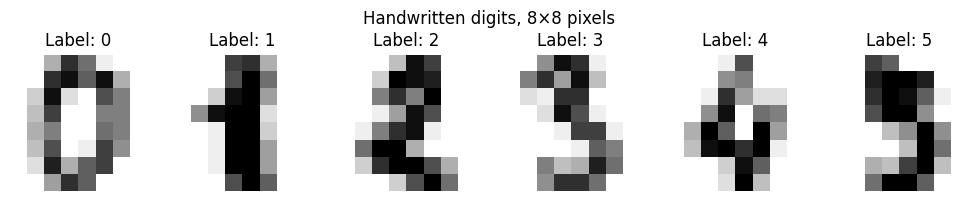

In [10]:
digits = load_digits()
images = (digits.images.astype("float32") / 16.0)[:, None, :, :]
labels = digits.target.astype("int64")

tr_idx, te_idx = train_test_split(
    np.arange(len(labels)), test_size=0.25, random_state=SEED, stratify=labels
)
Xdig_train = torch.tensor(images[tr_idx])
ydig_train = torch.tensor(labels[tr_idx])
Xdig_test = torch.tensor(images[te_idx])
ydig_test = torch.tensor(labels[te_idx])

fig, axs = plt.subplots(1, 6, figsize=(10, 2))
for ax, im, label in zip(axs, images[:6], labels[:6]):
    ax.imshow(im[0], cmap="gray_r", vmin=0, vmax=1)
    ax.set_title(f"Label: {label}")
    ax.axis("off")
plt.suptitle("Handwritten digits, 8×8 pixels")
plt.tight_layout()
plt.show()

,Epoch,Train loss,Test accuracy
0,1,2.288,0.182
1,2,2.117,0.480
2,3,1.518,0.684
3,4,0.910,0.742
4,5,0.648,0.802
5,6,0.517,0.869
6,7,0.384,0.860
7,8,0.328,0.864


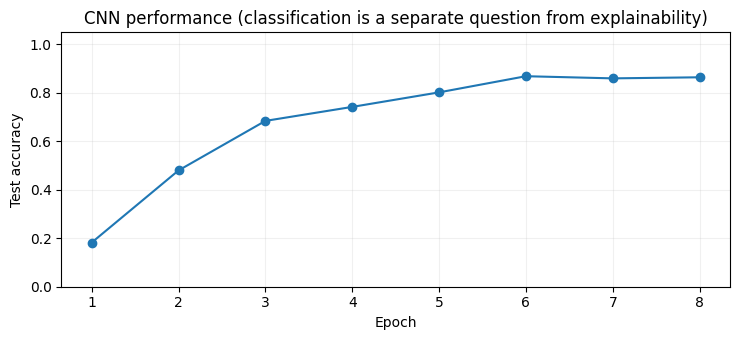

In [11]:
class TinyCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 8, kernel_size=3, padding=1), nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(8, 16, kernel_size=3, padding=1), nn.ReLU(),
            nn.MaxPool2d(2),
        )
        self.classifier = nn.Sequential(nn.Flatten(), nn.Linear(16 * 2 * 2, 32),
                                        nn.ReLU(), nn.Linear(32, 10))

    def forward(self, x):
        return self.classifier(self.features(x))

cnn = TinyCNN()
train_loader = DataLoader(TensorDataset(Xdig_train, ydig_train),
                          batch_size=64, shuffle=True)
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(cnn.parameters(), lr=0.003)

history = []
for epoch in range(1, 9):
    cnn.train()
    running = 0.0
    for xb, yb in train_loader:
        optimizer.zero_grad()
        logits = cnn(xb)
        loss = criterion(logits, yb)
        loss.backward()
        optimizer.step()
        running += float(loss.item()) * len(xb)
    cnn.eval()
    with torch.no_grad():
        test_pred = cnn(Xdig_test).argmax(1)
        test_accuracy = float((test_pred == ydig_test).float().mean())
    history.append((epoch, running / len(Xdig_train), test_accuracy))

training_summary = pd.DataFrame(history, columns=["Epoch", "Train loss", "Test accuracy"])
display(training_summary.round(3))
fig, ax = plt.subplots(figsize=(7.5, 3.5))
ax.plot(training_summary["Epoch"], training_summary["Test accuracy"], marker="o")
ax.set_ylim(0, 1.05)
ax.set_xlabel("Epoch")
ax.set_ylabel("Test accuracy")
ax.set_title("CNN performance (classification is a separate question from explainability)")
plt.tight_layout()
plt.show()

### 4.1 Choose one image and one target

A saliency map is **class-specific**. To compare methods fairly, keep the same **image, target class, score (logit), and baseline** wherever appropriate.

We start with a correctly classified sample so the target is obvious, then later try a **misclassified** example. We deliberately select a correct example; do not interpret this as representative of all cases.

Chosen index: 1, truth: 0, prediction: 0, confidence: 0.973


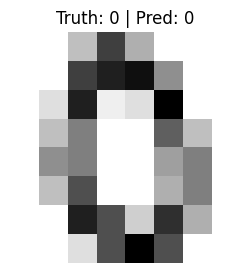

In [12]:
cnn.eval()
with torch.no_grad():
    all_logits = cnn(Xdig_test)
    all_probs = all_logits.softmax(dim=1)
    all_preds = all_probs.argmax(dim=1)
    correct = torch.where(all_preds == ydig_test)[0]
    incorrect = torch.where(all_preds != ydig_test)[0]

chosen = int(correct[0]) if len(correct) else 0
sample = Xdig_test[chosen:chosen+1].clone()
true_class = int(ydig_test[chosen])
target_class = int(all_preds[chosen])
print(f"Chosen index: {chosen}, truth: {true_class}, prediction: {target_class}, confidence: {float(all_probs[chosen,target_class]):.3f}")

fig, ax = plt.subplots(figsize=(3, 3))
ax.imshow(sample[0, 0], cmap="gray_r", vmin=0, vmax=1)
ax.set_title(f"Truth: {true_class} | Pred: {target_class}")
ax.axis("off")
plt.show()

### 4.2 Vanilla gradient saliency

Compute the gradient of the **target logit** with respect to every input pixel:

\[
S_i = \left|\frac{\partial f_c(x)}{\partial x_i}\right|
\]

This measures **local sensitivity** of the chosen logit to infinitesimal pixel changes. We use absolute gradients to show strength; that **removes the direction** of an effect. A bright pixel is not necessarily necessary, sufficient, or human-interpretable.

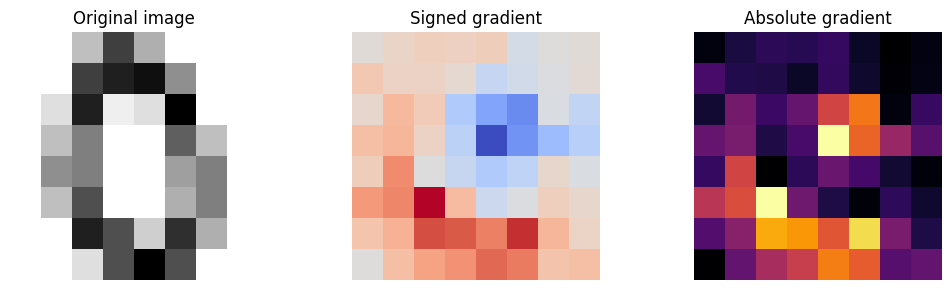

In [13]:
def vanilla_saliency(model, image, target):
    model.eval()
    x = image.detach().clone().requires_grad_(True)
    selected_logit = model(x)[0, target]
    grad = torch.autograd.grad(selected_logit, x)[0]
    return grad.detach()[0, 0].numpy()

saliency_signed = vanilla_saliency(cnn, sample, target_class)
saliency_abs = np.abs(saliency_signed)

fig, axes = plt.subplots(1, 3, figsize=(10.5, 3))
axes[0].imshow(sample[0, 0], cmap="gray_r", vmin=0, vmax=1)
axes[0].set_title("Original image")
axes[1].imshow(saliency_signed, cmap="coolwarm", vmin=-np.max(saliency_abs), vmax=np.max(saliency_abs))
axes[1].set_title("Signed gradient")
axes[2].imshow(saliency_abs, cmap="inferno")
axes[2].set_title("Absolute gradient")
for ax in axes: ax.axis("off")
plt.tight_layout()
plt.show()

### 4.3 Integrated Gradients (IG): from baseline to input

Vanilla gradients ask **"what changes the score nearby?"** IG asks **"how much attribution accumulates as we move from baseline to this input?"**

\[
IG_i(x) = (x_i-x'_i)\int_{\alpha=0}^{1}
  \frac{\partial f_c(x'+\alpha(x-x'))}{\partial x_i}\,d\alpha
\]

For this notebook, \(f_c\) is the class logit and \(x'\) is a **black / zero-valued image**. We approximate the integral with the **trapezoid rule**, without extra explainability libraries.

**Completeness check:** \(\sum_i IG_i(x)\) should be approximately \(f_c(x)-f_c(x')\). Accuracy improves with more integration steps, but the explanation still depends on the baseline.

f_c(image) - f_c(black baseline): 5.4403
Sum Integrated Gradients:         5.4267
Absolute approximation error:    0.0136


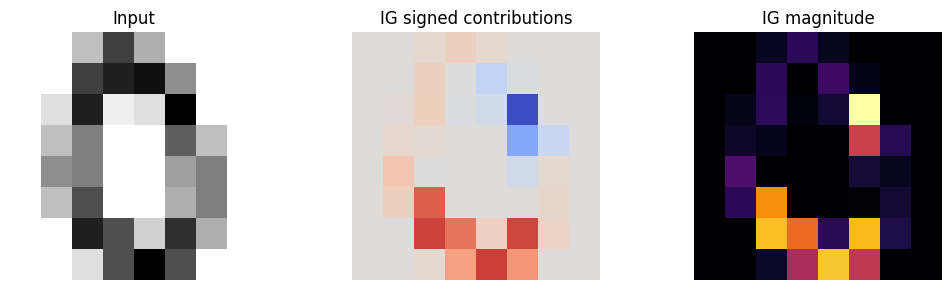

In [14]:
def integrated_gradients(model, image, target, baseline=None, steps=64):
    model.eval()
    x = image.detach().clone()
    b = torch.zeros_like(x) if baseline is None else baseline.detach().clone()
    grads = []
    for alpha in torch.linspace(0, 1, steps + 1):
        path_point = (b + alpha * (x - b)).requires_grad_(True)
        logit = model(path_point)[0, target]
        grad = torch.autograd.grad(logit, path_point)[0]
        grads.append(grad.detach())
    all_grads = torch.stack(grads)
    integral = (all_grads[0] / 2 + all_grads[-1] / 2 + all_grads[1:-1].sum(dim=0)) / steps
    return ((x - b) * integral).detach()

baseline = torch.zeros_like(sample)
ig = integrated_gradients(cnn, sample, target_class, baseline=baseline, steps=64)
with torch.no_grad():
    logit_difference = float(cnn(sample)[0, target_class] - cnn(baseline)[0, target_class])
ig_total = float(ig.sum())
print(f"f_c(image) - f_c(black baseline): {logit_difference:.4f}")
print(f"Sum Integrated Gradients:         {ig_total:.4f}")
print(f"Absolute approximation error:    {abs(logit_difference - ig_total):.4f}")

ig_np = ig[0, 0].numpy()
limit = np.max(np.abs(ig_np)) + 1e-9
fig, axes = plt.subplots(1, 3, figsize=(10.5, 3))
axes[0].imshow(sample[0, 0], cmap="gray_r", vmin=0, vmax=1)
axes[0].set_title("Input")
axes[1].imshow(ig_np, cmap="coolwarm", vmin=-limit, vmax=limit)
axes[1].set_title("IG signed contributions")
axes[2].imshow(np.abs(ig_np), cmap="inferno")
axes[2].set_title("IG magnitude")
for ax in axes: ax.axis("off")
plt.tight_layout()
plt.show()

### 4.4 Occlusion: a perturbation-based explanation

Instead of using gradients, **hide a small image patch** and measure how much the chosen target's logit changes:

\[
O(p) = f_c(x) - f_c(x\text{ with patch }p\text{ replaced by baseline})
\]

Positive: hiding the patch **reduces** the target logit. Negative: hiding the patch **increases** it. This is more directly tied to prediction perturbations, but still depends on patch size, baseline, and whether the occluded image is realistic.

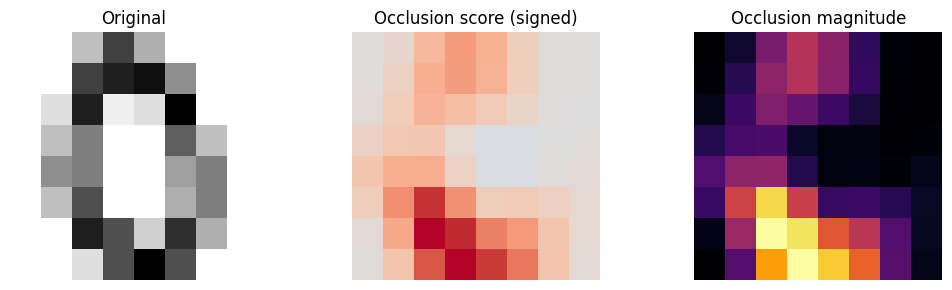

In [15]:
def occlusion_map(model, image, target, patch_size=2, fill_value=0.0):
    model.eval()
    height, width = image.shape[-2:]
    with torch.no_grad():
        original_score = float(model(image)[0, target])
    scores = np.zeros((height, width), dtype=float)
    counts = np.zeros_like(scores)
    for row in range(height - patch_size + 1):
        for col in range(width - patch_size + 1):
            modified = image.detach().clone()
            modified[:, :, row:row+patch_size, col:col+patch_size] = fill_value
            with torch.no_grad():
                changed_score = float(model(modified)[0, target])
            drop = original_score - changed_score
            scores[row:row+patch_size, col:col+patch_size] += drop
            counts[row:row+patch_size, col:col+patch_size] += 1
    return scores / np.maximum(counts, 1)

occlusion = occlusion_map(cnn, sample, target_class, patch_size=2)
occlusion_limit = np.max(np.abs(occlusion)) + 1e-9
fig, axes = plt.subplots(1, 3, figsize=(10.5, 3))
axes[0].imshow(sample[0, 0], cmap="gray_r", vmin=0, vmax=1)
axes[0].set_title("Original")
axes[1].imshow(occlusion, cmap="coolwarm", vmin=-occlusion_limit, vmax=occlusion_limit)
axes[1].set_title("Occlusion score (signed)")
axes[2].imshow(np.abs(occlusion), cmap="inferno")
axes[2].set_title("Occlusion magnitude")
for ax in axes: ax.axis("off")
plt.tight_layout()
plt.show()

### 4.5 Same example, three methods

**Do not assume agreement means truth.** Saliency, IG, and occlusion ask **different questions**. For visual comparison, the maps below are min-max normalized for plotting only; normalization **destroys comparisons of absolute magnitude between methods**.

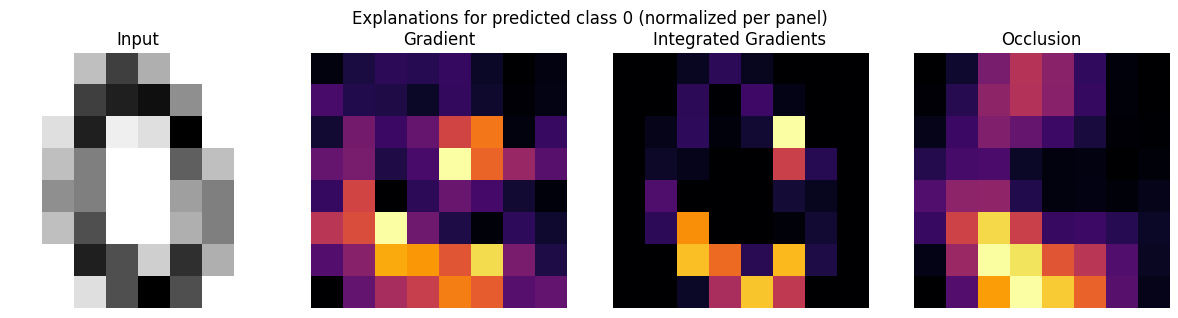

In [16]:
def normalize_for_display(arr):
    a = np.abs(np.asarray(arr, dtype=float))
    return (a - a.min()) / (a.max() - a.min() + 1e-9)

fig, axes = plt.subplots(1, 4, figsize=(12.2, 3.2))
for ax, picture, title, cmap in zip(
    axes,
    [sample[0, 0].numpy(), normalize_for_display(saliency_abs),
     normalize_for_display(ig_np), normalize_for_display(occlusion)],
    ["Input", "Gradient", "Integrated Gradients", "Occlusion"],
    ["gray_r", "inferno", "inferno", "inferno"],
):
    ax.imshow(picture, cmap=cmap)
    ax.set_title(title)
    ax.axis("off")
plt.suptitle(f"Explanations for predicted class {target_class} (normalized per panel)")
plt.tight_layout()
plt.show()

### 4.6 Sanity check: does an explanation respond when model weights change?

An explanation should depend on what the model actually learned. One simple **model-parameter randomization check** changes the final learned layer without retraining, then asks whether the saliency looks different.

This is *one* sanity check, not a proof of correctness. A high similarity is concerning; a low similarity doesn't establish faithfulness. We're comparing **absolute** saliency using pixelwise Pearson correlation, which has limitations.

Abs-saliency Pearson correlation after final-layer randomization: 0.369


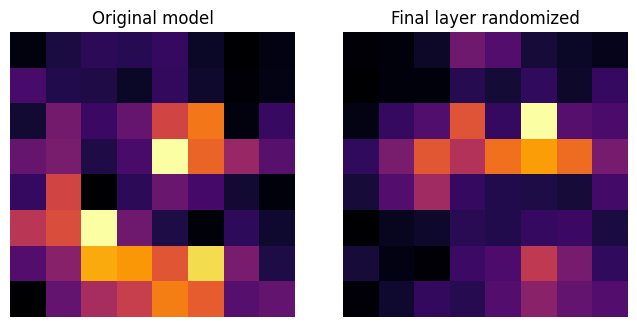

In [17]:
randomized = copy.deepcopy(cnn)
with torch.no_grad():
    final_layer = randomized.classifier[-1]
    nn.init.normal_(final_layer.weight, mean=0.0, std=0.25)
    nn.init.zeros_(final_layer.bias)

random_saliency = np.abs(vanilla_saliency(randomized, sample, target_class))
if np.std(saliency_abs) > 0 and np.std(random_saliency) > 0:
    similarity = float(np.corrcoef(saliency_abs.ravel(), random_saliency.ravel())[0, 1])
else:
    similarity = float('nan')
print(f"Abs-saliency Pearson correlation after final-layer randomization: {similarity:.3f}")
fig, axes = plt.subplots(1, 2, figsize=(6.8, 3.3))
axes[0].imshow(saliency_abs, cmap="inferno")
axes[0].set_title("Original model")
axes[1].imshow(random_saliency, cmap="inferno")
axes[1].set_title("Final layer randomized")
for ax in axes: ax.axis("off")
plt.tight_layout()
plt.show()

### 4.7 A quantitative faithfulness probe: deletion

**Question:** If the explanation highlights important pixels, does removing those pixels reduce the model's target score faster than removing random pixels?

Below we progressively zero out pixels in rank order of **absolute IG** and compare with a fixed random order. This is a crude **deletion test**: masking creates out-of-distribution inputs, and using absolute values mixes positive and negative contributions. Consequently, the result is a diagnostic—not a universal benchmark.

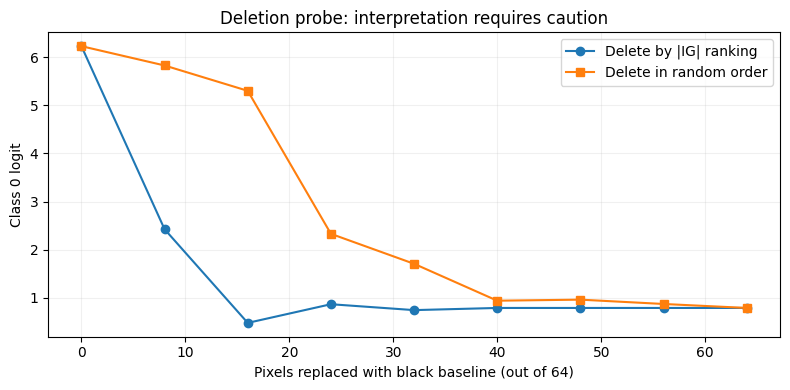

In [18]:
def deletion_curve(model, image, target, pixel_order, step=8):
    n_pixels = image.shape[-1] * image.shape[-2]
    budgets = sorted(set([0] + list(range(step, n_pixels + 1, step)) + [n_pixels]))
    values = []
    for budget in budgets:
        altered = image.detach().clone()
        flat = altered.view(-1)
        flat[np.asarray(pixel_order[:budget], dtype=int)] = 0.0
        with torch.no_grad():
            values.append(float(model(altered)[0, target]))
    return np.asarray(budgets), np.asarray(values)

ig_ranking = np.argsort(-np.abs(ig_np).ravel())
random_ranking = np.random.default_rng(SEED).permutation(ig_np.size)
k_ig, score_ig = deletion_curve(cnn, sample, target_class, ig_ranking)
k_r, score_random = deletion_curve(cnn, sample, target_class, random_ranking)
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(k_ig, score_ig, marker="o", label="Delete by |IG| ranking")
ax.plot(k_r, score_random, marker="s", label="Delete in random order")
ax.set_xlabel("Pixels replaced with black baseline (out of 64)")
ax.set_ylabel(f"Class {target_class} logit")
ax.set_title("Deletion probe: interpretation requires caution")
ax.legend()
plt.tight_layout()
plt.show()

### Exercise B — test the deep-learning explanations (15 minutes)

1. **Change the target**: keep the image but explain the logit of another digit, e.g. `(target_class + 1) % 10`. Do the highlighted pixels move?
2. **Change the baseline**: run IG with `torch.full_like(sample, 0.5)` instead of a black image. Compare heatmaps and completeness errors.
3. **Change the patch**: repeat occlusion with `patch_size=1`, then `3`. What visual differences appear?
4. **Use an error case**: select `incorrect[0]` if it exists. Explain the *predicted* class, then the *true* class. How do they differ?
5. **Challenge deletion**: Why might removing the pixels with the largest absolute attributions sometimes **increase** the class logit?

**Starter (uncomment and edit):**

```python
# alternative_target = (target_class + 1) % 10
# alternative_ig = integrated_gradients(cnn, sample, alternative_target)
# gray_baseline = torch.full_like(sample, 0.5)
# ig_gray = integrated_gradients(cnn, sample, target_class, baseline=gray_baseline)
# patch1 = occlusion_map(cnn, sample, target_class, patch_size=1)
```

## 5 · Which explanation should you use?

| Your question | First method to try | Crucial limitation |
|---|---|---|
| How does a simple model combine features? | Standardized coefficients or rules | Correlation, scaling, wrong specification |
| Which features does this trained classifier rely on across cases? | Held-out permutation importance | Correlated features, metric sensitivity |
| How does a model's response vary with one feature? | PDP with ICE | Unrealistic combinations, averaging hides heterogeneity |
| Why this tabular prediction relative to a baseline? | Linear contributions / SHAP | Background choice; not causal |
| Which image pixels locally affect a class logit? | Gradient saliency | Noisy, saturated, local sensitivity |
| What accumulates from a reference image? | Integrated Gradients | Baseline and path dependence |
| Which image regions change the score when hidden? | Occlusion | Patch choice; out-of-distribution masking |
| What change *should a person make* to change an outcome? | **Causal + domain analysis**, not just XAI | Feasibility, ethics, confounding, intervention effects |

### Five-question explanation scorecard

For every explanation, ask:
1. **Audience:** Is this for a researcher, practitioner, affected individual, or auditor?
2. **Scope:** Local or global, and what target/output is being explained?
3. **Fidelity:** Would perturbation or a surrogate test support the explanation?
4. **Robustness:** Would small input changes, background changes, or another random seed change it?
5. **Actionability:** Could the proposed change happen in the real world, and is the explanation causal or merely associative?

**Research-level takeaway:** *Explanations are hypotheses about model behavior. Evaluate them as rigorously as predictions.*

## 6 · Mini-project / assessment (20–30 minutes)

Choose **one** of these scenarios:

**A. Tabular model audit:** A hospital asks why its classifier predicted one case as benign. Compare a global and local explanation, discuss correlation, and explain why the output is *not* clinical advice.

**B. Image model audit:** A teammate claims the digit CNN “looks at the right pixels.” Compare IG, gradient, occlusion, and at least one sanity or deletion check. Defend or reject the claim.

**Deliverable:** a concise 1-page model-explanation report with these four headings:

1. **Claim:** the precise model behavior you are attempting to explain.
2. **Evidence:** two plots or quantitative checks, with the target and baseline specified.
3. **Failure mode:** one test that weakens your explanation or exposes uncertainty.
4. **Conclusion:** what you can say, what you cannot say, and one next experiment.

**Suggested rubric (10 points):** correct technical interpretation (3), meaningful comparison (2), explanation evaluation (3), careful limitation / communication (2).

### Exit ticket

**Explain in one sentence each:**
- Why a high-accuracy model is not necessarily explainable.
- Why a beautiful saliency map is not necessarily faithful.
- Why “changing an important feature” is not necessarily a real-world intervention.

## 7 · References and further exploration

Foundational readings (searchable by paper title/DOI):

1. Ribeiro, Singh & Guestrin (2016). **“Why Should I Trust You?”: Explaining the Predictions of Any Classifier.** KDD. Introduces LIME (not implemented here).
2. Lundberg & Lee (2017). **A Unified Approach to Interpreting Model Predictions.** NeurIPS. Introduces SHAP.
3. Sundararajan, Taly & Yan (2017). **Axiomatic Attribution for Deep Networks.** ICML. Introduces Integrated Gradients.
4. Adebayo et al. (2018). **Sanity Checks for Saliency Maps.** NeurIPS. Motivates model and data randomization tests.
5. Molnar, *Interpretable Machine Learning* (open online book): https://christophm.github.io/interpretable-ml-book/
6. scikit-learn documentation, permutation importance and partial dependence: https://scikit-learn.org/stable/inspection.html

**Optional extensions:** LIME for local surrogate explanations; concept-level explanations such as TCAV; Grad-CAM for larger CNNs; explanation stability and uncertainty; causal explanation / recourse.

**Reproducibility note:** Numerical results can change across PyTorch/scikit-learn versions and hardware. Interpret the *method* and perform checks rather than memorizing plot shapes.